In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm
import jax.numpy as jnp
import jax
from scipy.special import erfc, erfcinv
from functools import partial, wraps

from lib import neurons, input_gen, driver, utils, base

In [32]:
# ns=200
# nd=300
# n = 10
# rng = jax.random.PRNGKey(12345)

beta= 5.75911 # non-int params3
b = 2.55
bk = 4.0

ns=200
nd=300
n = 10
rng = jax.random.PRNGKey(12345)

# beta= 5.85277 # params3
# b = 2.55
# bk = 4.0

hyper = neurons.HyperConfig1(nd=nd, ns=ns, n=n, b=b, bk=bk, beta=beta)
hyperD = neurons.HyperDynConfig1(b=b, bk=bk, beta=beta)
# neuron = neurons.Neuron_Decay_NonInt(hyperparameters=hyper)
# neuron = neurons.Neuron_Decay_Int_Variable_n(hyperparameters=hyper)
# neuron = neurons.Neuron_Decay_Int_Variable_n_min1(hyperparameters=hyper)
neuron = neurons.Neuron_Decay_Int(hyperparameters=hyper)

rng, subkey = jax.random.split(rng)
xs_gen = input_gen.Normal(nd, ns)
# xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=8, key=subkey)
# xs_gen = input_gen.Normal_Corr_across_Dendrites(nd, ns, coeff=4, key=subkey)

rng, subkey = jax.random.split(rng)
my_driver = driver.Driver1_stepSize_record(neuron, xs_gen, subkey, hyperD, initial_state=None, resample_every=1000, n_tested_patterns=1000)

In [33]:
my_driver.run(
            n_init_steps=10000,
            n_steps_phase2=20000,
            n_steps_phase3=10000,
            test_every_phase3=1,
            bs=jnp.array([b])
        ) 

In [34]:
stepSizes_record = my_driver.steady_record.flatten()
stepSizes_record = stepSizes_record[jnp.nonzero(stepSizes_record)]

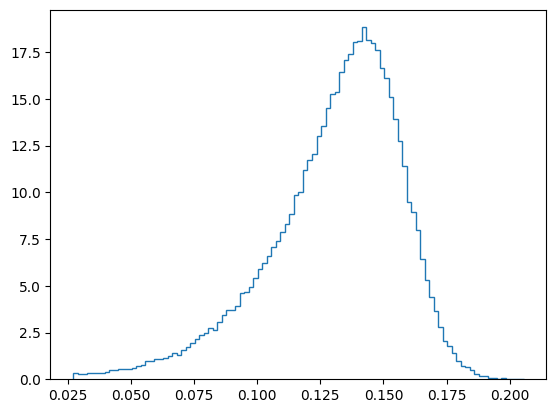

In [35]:
max_size = jnp.max(stepSizes_record)
min_size = jnp.min(stepSizes_record)
plt.hist(stepSizes_record, bins=100, density=True, histtype='step');

In [36]:
np.save("../data/fixed_params/stepSize_distribution/int_params3.npy", stepSizes_record)
# np.save("../tmp_data/int_params3.npy", wlens_array)

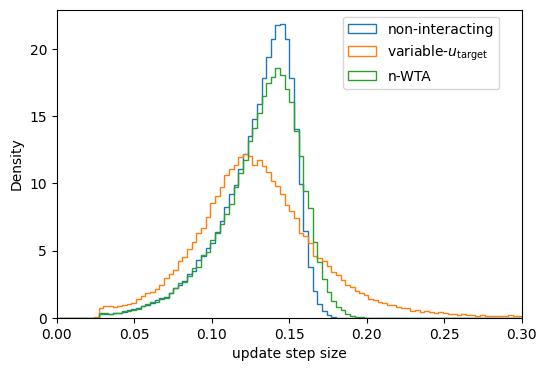

In [3]:
stepSizes_nonInt = np.load("../data/fixed_params/stepSize_distribution/nonInt_params3.npy")
stepSizes_int_variable_n_min1 = np.load("../data/fixed_params/stepSize_distribution/int_variableN_min1_params3.npy")
stepSizes_int = np.load("../data/fixed_params/stepSize_distribution/int_params3.npy")

plt.figure(figsize=(6,4))
xmin = 0.
xmax = 0.3
plt.hist(stepSizes_nonInt, bins=100, range=(xmin, xmax), density=True, histtype="step", label="non-interacting");
plt.hist(stepSizes_int_variable_n_min1, bins=100, range=(xmin, xmax), density=True, histtype="step", label=r'variable-$u_{\text{target}}$');
plt.hist(stepSizes_int, bins=100, range=(xmin, xmax), density=True, histtype="step", label="n-WTA");
plt.xlabel("update step size");
plt.ylabel("Density");
plt.xlim(xmin, xmax)
plt.legend(bbox_to_anchor=(0.6, 1), loc='upper left');

# plt.savefig("../figures/stepSize_distribution_params3.png")

In [5]:
np.mean(stepSizes_nonInt), np.mean(stepSizes_int_variable_n_min1), np.mean(stepSizes_int)

(np.float32(0.12836094), np.float32(0.13010263), np.float32(0.13047907))

In [ ]:
np.std(stepSizes_nonInt), np.std(stepSizes_int_variable_n_min1), np.std(stepSizes_int)

(np.float32(0.024415653), np.float32(0.043453787), np.float32(0.026207926))

: 